# Data ingestion

In [1]:
import boto3
import datetime
import json
import os

In [2]:
os.chdir("c:\\Users\\Dominic\\Desktop\\data_dags")

In [3]:
os.getcwd()

'c:\\Users\\Dominic\\Desktop\\data_dags'

## Employment data - Bureau of Labour Statistics (BLS)

In [ ]:
from src.bureau_of_labour_stats.tools import fetch_data_bls_api, naming_convention_bls

In [5]:
URL = "https://api.bls.gov/publicAPI/v1/timeseries/data/"

Possible period codes for BLS data:
* M01 - M12: "January" - "Decemeber"
* M13: "Annual average"
* Q01 - Q04: "1st Quarter" - "4th Quarter"
* Q05: "Quarterly Data Program Annual Average"

In [6]:
SERIES_IDS = {
    "Civilian Labor Force (Seasonally Adjusted)": "LNS11000000",
    "Civilian Employment (Seasonally Adjusted)": "LNS12000000",
    "Civilian Unemployment (Seasonally Adjusted)": "LNS13000000",
    "Unemployment Rate (Seasonally Adjusted)": "LNS14000000",
    "Total Nonfarm Employment - Seasonally Adjusted": "CES0000000001",
    "Total Private Average Weekly Hours of All Employees - Seasonally Adjusted": "CES0500000002",
    "Total Private Average Weekly Hours of Prod. and Nonsup. Employees - Seasonally Adjusted": "CES0500000007",
    "Total Private Average Hourly Earnings of All Employees - Seasonally Adjusted": "CES0500000003",
    "Total Private Average Hourly Earnings of Prod. and Nonsup. Employees - Seasonally Adjusted": "CES0500000008"
}

In [7]:
today_day = datetime.datetime.today().strftime("%Y-%m-%d")
print(today_day)

2026-10-08


In [8]:
naming_convention = [
    naming_convention_bls(name, series_id, today_day)
    for name, series_id in SERIES_IDS.items()
]
naming_convention

['BLS/Civilian-Labor-Force--Seasonally-Adjusted-/LNS11000000/2026-10-08/series.json',
 'BLS/Civilian-Employment--Seasonally-Adjusted-/LNS12000000/2026-10-08/series.json',
 'BLS/Civilian-Unemployment--Seasonally-Adjusted-/LNS13000000/2026-10-08/series.json',
 'BLS/Unemployment-Rate--Seasonally-Adjusted-/LNS14000000/2026-10-08/series.json',
 'BLS/Total-Nonfarm-Employment---Seasonally-Adjusted/CES0000000001/2026-10-08/series.json',
 'BLS/Total-Private-Average-Weekly-Hours-of-All-Employees---Seasonally-Adjusted/CES0500000002/2026-10-08/series.json',
 'BLS/Total-Private-Average-Weekly-Hours-of-Prod.-and-Nonsup.-Employees---Seasonally-Adjusted/CES0500000007/2026-10-08/series.json',
 'BLS/Total-Private-Average-Hourly-Earnings-of-All-Employees---Seasonally-Adjusted/CES0500000003/2026-10-08/series.json',
 'BLS/Total-Private-Average-Hourly-Earnings-of-Prod.-and-Nonsup.-Employees---Seasonally-Adjusted/CES0500000008/2026-10-08/series.json']

In [9]:
s3_client = boto3.client("s3")
s3_resource = boto3.resource("s3")

In [10]:
response = s3_client.list_buckets()
for bucket in response["Buckets"]:
    print(bucket)

{'Name': 'garage-bucket', 'CreationDate': datetime.datetime(2026, 9, 25, 13, 31, 39, 128000, tzinfo=tzutc())}


In [11]:
response = s3_client.list_objects(Bucket="garage-bucket")
obj = response.get("Contents", [])
obj_files = [o["Key"] for o in obj]
print(obj)

[{'Key': 'BLS/Civilian-Employment--Seasonally-Adjusted-/LNS12000000/2026-10-06/series.json', 'LastModified': datetime.datetime(2026, 10, 6, 21, 59, 12, 828000, tzinfo=tzutc()), 'ETag': '"3f7c214a738be1ea7ce1ee4a37ef6582"', 'Size': 3605, 'StorageClass': 'STANDARD'}, {'Key': 'BLS/Civilian-Labor-Force--Seasonally-Adjusted-/LNS11000000/2026-10-06/series.json', 'LastModified': datetime.datetime(2026, 10, 6, 21, 59, 12, 815000, tzinfo=tzutc()), 'ETag': '"489268b53689b3c81bd53072ee6692ef"', 'Size': 3605, 'StorageClass': 'STANDARD'}, {'Key': 'BLS/Civilian-Unemployment--Seasonally-Adjusted-/LNS13000000/2026-10-06/series.json', 'LastModified': datetime.datetime(2026, 10, 6, 21, 59, 12, 838000, tzinfo=tzutc()), 'ETag': '"a9568c273cadefcdd889e98207051db2"', 'Size': 3399, 'StorageClass': 'STANDARD'}, {'Key': 'BLS/Total-Nonfarm-Employment---Seasonally-Adjusted/CES0000000001/2026-10-06/series.json', 'LastModified': datetime.datetime(2026, 10, 6, 21, 59, 12, 999000, tzinfo=tzutc()), 'ETag': '"2502c74f

In [12]:
print(obj_files)

['BLS/Civilian-Employment--Seasonally-Adjusted-/LNS12000000/2026-10-06/series.json', 'BLS/Civilian-Labor-Force--Seasonally-Adjusted-/LNS11000000/2026-10-06/series.json', 'BLS/Civilian-Unemployment--Seasonally-Adjusted-/LNS13000000/2026-10-06/series.json', 'BLS/Total-Nonfarm-Employment---Seasonally-Adjusted/CES0000000001/2026-10-06/series.json', 'BLS/Total-Private-Average-Hourly-Earnings-of-All-Employees---Seasonally-Adjusted/CES0500000003/2026-10-06/series.json', 'BLS/Total-Private-Average-Hourly-Earnings-of-Prod.-and-Nonsup.-Employees---Seasonally-Adjusted/CES0500000008/2026-10-06/series.json', 'BLS/Total-Private-Average-Weekly-Hours-of-All-Employees---Seasonally-Adjusted/CES0500000002/2026-10-06/series.json', 'BLS/Total-Private-Average-Weekly-Hours-of-Prod.-and-Nonsup.-Employees---Seasonally-Adjusted/CES0500000007/2026-10-06/series.json', 'BLS/Unemployment-Rate--Seasonally-Adjusted-/LNS14000000/2026-10-06/series.json']


In [20]:
results = fetch_data_bls_api(
    url=URL,
    series_id=[v for k, v in SERIES_IDS.items() if naming_convention_bls(k, v, today_day) not in obj_files]
)

In [22]:
results.keys()

dict_keys(['series'])

In [23]:
len(results["series"])

0

In [24]:
results["series"][0].keys()

IndexError: list index out of range

In [25]:
results["series"][0]["seriesID"]

IndexError: list index out of range

In [26]:
results["series"][0]["data"][0].keys()

IndexError: list index out of range

In [27]:
results["series"][0]["data"][0]

IndexError: list index out of range

## Uploading data to S3

In [13]:
print(obj)

[{'Key': 'BLS/Civilian-Employment--Seasonally-Adjusted-/LNS12000000/2026-10-06/series.json', 'LastModified': datetime.datetime(2026, 10, 6, 21, 59, 12, 828000, tzinfo=tzutc()), 'ETag': '"3f7c214a738be1ea7ce1ee4a37ef6582"', 'Size': 3605, 'StorageClass': 'STANDARD'}, {'Key': 'BLS/Civilian-Labor-Force--Seasonally-Adjusted-/LNS11000000/2026-10-06/series.json', 'LastModified': datetime.datetime(2026, 10, 6, 21, 59, 12, 815000, tzinfo=tzutc()), 'ETag': '"489268b53689b3c81bd53072ee6692ef"', 'Size': 3605, 'StorageClass': 'STANDARD'}, {'Key': 'BLS/Civilian-Unemployment--Seasonally-Adjusted-/LNS13000000/2026-10-06/series.json', 'LastModified': datetime.datetime(2026, 10, 6, 21, 59, 12, 838000, tzinfo=tzutc()), 'ETag': '"a9568c273cadefcdd889e98207051db2"', 'Size': 3399, 'StorageClass': 'STANDARD'}, {'Key': 'BLS/Total-Nonfarm-Employment---Seasonally-Adjusted/CES0000000001/2026-10-06/series.json', 'LastModified': datetime.datetime(2026, 10, 6, 21, 59, 12, 999000, tzinfo=tzutc()), 'ETag': '"2502c74f

In [29]:
for counter in range(len(naming_convention)):
    name = naming_convention[counter]
    if name not in obj:
        s3_object = s3_resource.Object(
            "garage-bucket",
            name
        )

        s3_object.put(
            Body=(
                bytes(
                    json.dumps(
                        results["series"][counter]["data"]
                    ).encode("UTF-8")
                )
            ),
            ContentType="application/json"
        )

IndexError: list index out of range

In [14]:
response = s3_client.list_objects(Bucket="garage-bucket")
obj = response.get("Contents", [])
print(obj)

[{'Key': 'BLS/Civilian-Employment--Seasonally-Adjusted-/LNS12000000/2026-10-06/series.json', 'LastModified': datetime.datetime(2026, 10, 6, 21, 59, 12, 828000, tzinfo=tzutc()), 'ETag': '"3f7c214a738be1ea7ce1ee4a37ef6582"', 'Size': 3605, 'StorageClass': 'STANDARD'}, {'Key': 'BLS/Civilian-Labor-Force--Seasonally-Adjusted-/LNS11000000/2026-10-06/series.json', 'LastModified': datetime.datetime(2026, 10, 6, 21, 59, 12, 815000, tzinfo=tzutc()), 'ETag': '"489268b53689b3c81bd53072ee6692ef"', 'Size': 3605, 'StorageClass': 'STANDARD'}, {'Key': 'BLS/Civilian-Unemployment--Seasonally-Adjusted-/LNS13000000/2026-10-06/series.json', 'LastModified': datetime.datetime(2026, 10, 6, 21, 59, 12, 838000, tzinfo=tzutc()), 'ETag': '"a9568c273cadefcdd889e98207051db2"', 'Size': 3399, 'StorageClass': 'STANDARD'}, {'Key': 'BLS/Total-Nonfarm-Employment---Seasonally-Adjusted/CES0000000001/2026-10-06/series.json', 'LastModified': datetime.datetime(2026, 10, 6, 21, 59, 12, 999000, tzinfo=tzutc()), 'ETag': '"2502c74f

# Analysis

In [43]:
import pandas
from matplotlib import pyplot as plt
import numpy as np
from src.bureau_of_labour_stats.tools import bls_transformations

In [16]:
bls_files = s3_client.list_objects(
    Bucket="garage-bucket",
    Prefix="BLS/"
)
bls_files.keys()

dict_keys(['ResponseMetadata', 'IsTruncated', 'Contents', 'Name', 'Prefix', 'MaxKeys', 'EncodingType'])

In [17]:
data = bls_files["Contents"]
data[0]

{'Key': 'BLS/Civilian-Employment--Seasonally-Adjusted-/LNS12000000/2026-10-06/series.json',
 'LastModified': datetime.datetime(2026, 10, 6, 21, 59, 12, 828000, tzinfo=tzutc()),
 'ETag': '"3f7c214a738be1ea7ce1ee4a37ef6582"',
 'Size': 3605,
 'StorageClass': 'STANDARD'}

In [18]:
civilian_employment = s3_client.get_object(Bucket="garage-bucket", Key=data[0]["Key"])["Body"]

In [19]:
civilian_employment = pandas.read_json(civilian_employment)

In [20]:
civilian_employment.head()

,year,period,periodName,latest,value,footnotes
0,2026,M09,September,true,163152,[{}]
1,2026,M08,August,NaN,162746,[{}]
2,2026,M07,July,NaN,162177,[{}]
3,2026,M06,June,NaN,162264,[{}]
4,2026,M05,May,NaN,162771,[{}]


In [21]:
civilian_employment.info()

<class 'pandas.DataFrame'>
RangeIndex: 33 entries, 0 to 32
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   year        33 non-null     int64 
 1   period      33 non-null     str   
 2   periodName  33 non-null     str   
 3   latest      1 non-null      str   
 4   value       33 non-null     str   
 5   footnotes   33 non-null     object
dtypes: int64(1), object(1), str(4)
memory usage: 1.7+ KB


In [22]:
civilian_employment.value.values

<StringArray>
['163152', '162746', '162177', '162264', '162771', '162622', '162848',
 '162912', '163097', '163992', '163760',      '-', '163656', '163370',
 '163140', '163327', '163244', '163898', '163509', '163338', '163831',
 '161586', '161159', '161444', '161813', '161429', '161297', '161152',
 '161180', '161438', '161462', '161083', '161133']
Length: 33, dtype: str

In [23]:
civilian_employment.period.unique()

<StringArray>
['M09', 'M08', 'M07', 'M06', 'M05', 'M04', 'M03', 'M02', 'M01', 'M12', 'M11',
 'M10']
Length: 12, dtype: str

In [ ]:
civilian_employment = bls_transformations(civilian_employment)

In [25]:
civilian_employment.describe()

,value
count,33.000000
mean,162494.666667
std,981.659649
min,161083.000000
25%,161444.000000
50%,162746.000000
75%,163327.000000
max,163992.000000


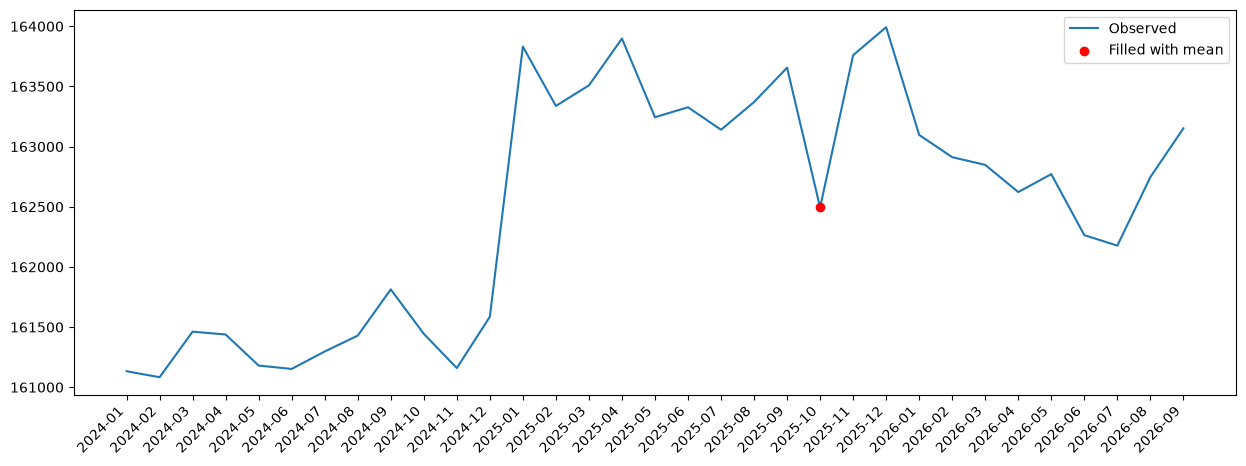

In [26]:
fig, ax = plt.subplots(figsize=(15, 5))

ax.plot(civilian_employment["year-period"], civilian_employment["value"], label="Observed")

ax.scatter(
    civilian_employment.loc[civilian_employment["filled"], "year-period"],
    civilian_employment.loc[civilian_employment["filled"], "value"],
    color="red",
    zorder=3,
    label="Filled with mean"
)

ax.set_xticks(civilian_employment["year-period"])
ax.set_xticklabels(civilian_employment["year-period"], rotation=45, ha="right");

ax.invert_xaxis()

ax.legend()

plt.show()

# Correlation

In [ ]:
import seaborn as sns

In [28]:
dfs = [pandas.read_json(s3_client.get_object(Bucket="garage-bucket", Key=data[n]["Key"])["Body"]) for n in range(len(data))]

In [31]:
dfs = [bls_transformations(df) for df in dfs]

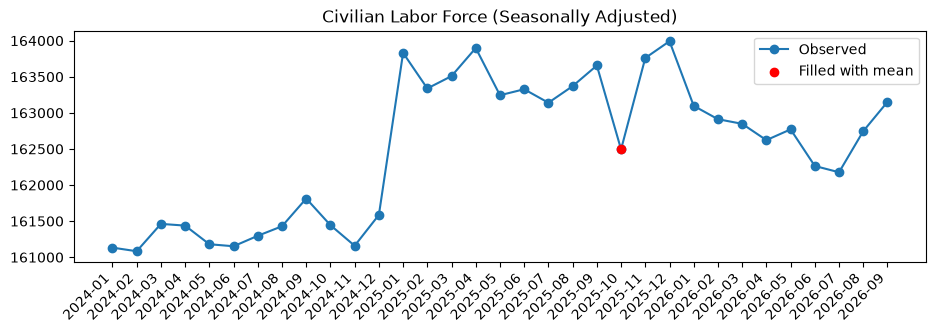

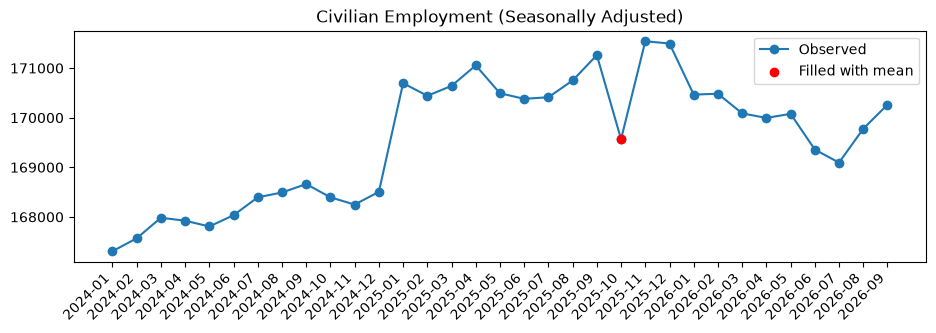

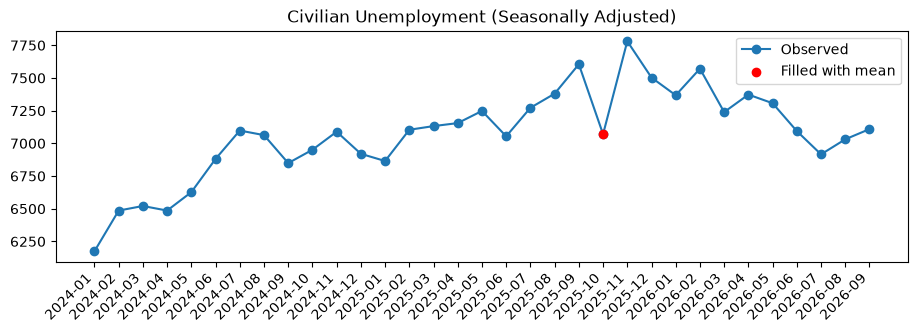

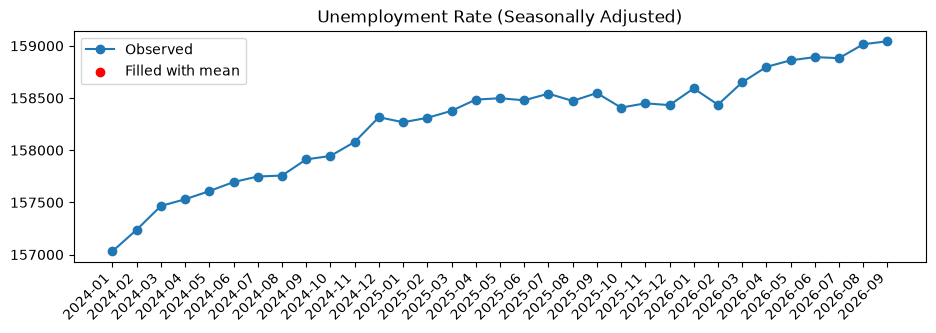

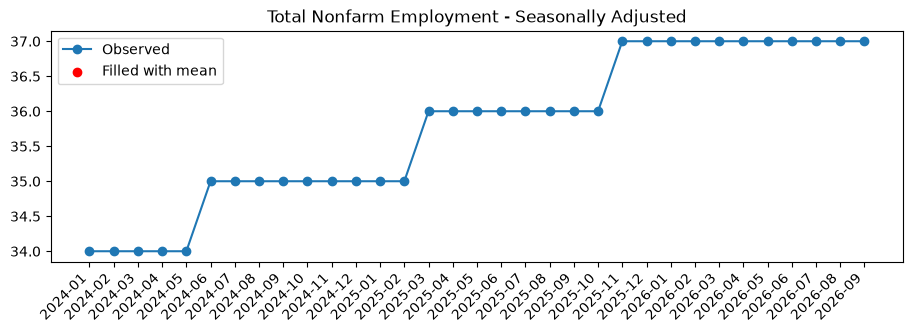

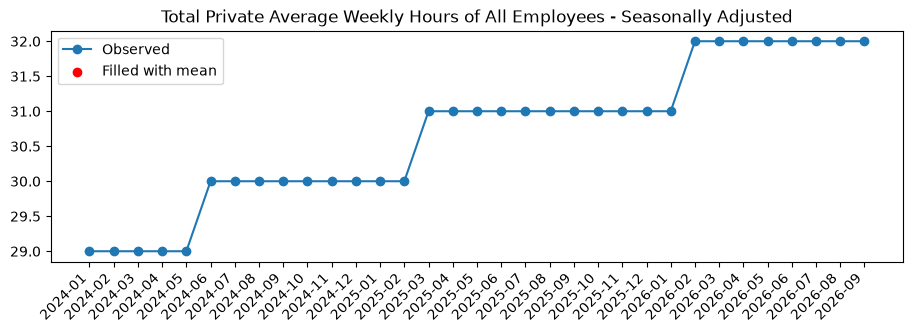

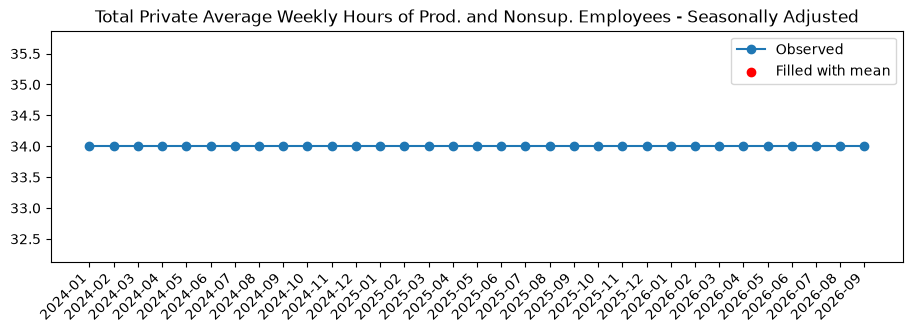

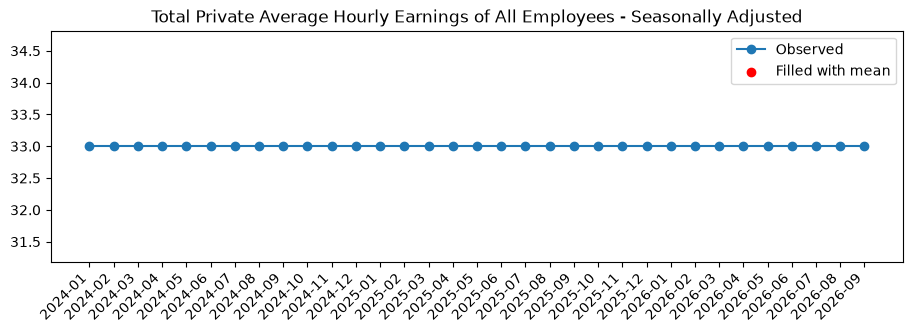

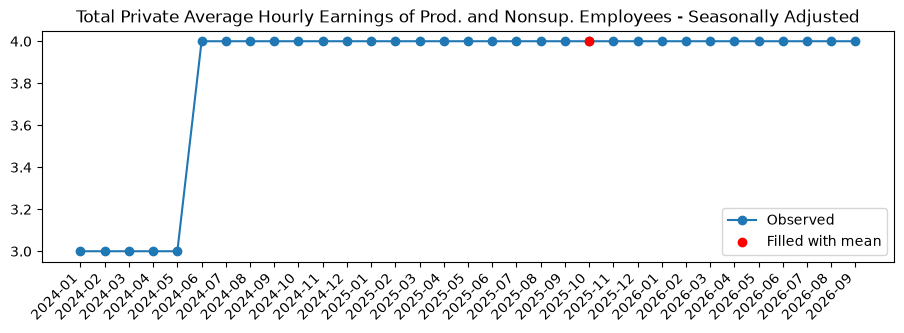

In [35]:
for counter in range(len(dfs)):
    df = dfs[counter]
    fig, ax = plt.subplots(figsize=(11, 3))

    ax.plot(df["year-period"], df["value"], label="Observed", marker="o")

    ax.scatter(
        df.loc[df["filled"], "year-period"],
        df.loc[df["filled"], "value"],
        color="red",
        zorder=3,
        label="Filled with mean"
    )

    ax.set_xticks(df["year-period"])
    ax.set_xticklabels(df["year-period"], rotation=45, ha="right");

    ax.invert_xaxis()

    ax.legend()

    plt.title(list(SERIES_IDS.keys())[counter])
    plt.show()

In [34]:
correlation = [[dfs[counter1]["value"].corr(dfs[counter2]["value"]) for counter1 in range(len(dfs))] for counter2 in range(len(dfs))];

c:\Users\Dominic\Desktop\data_dags\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\Dominic\Desktop\data_dags\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


In [35]:
correlation_matrix = pandas.DataFrame(correlation)

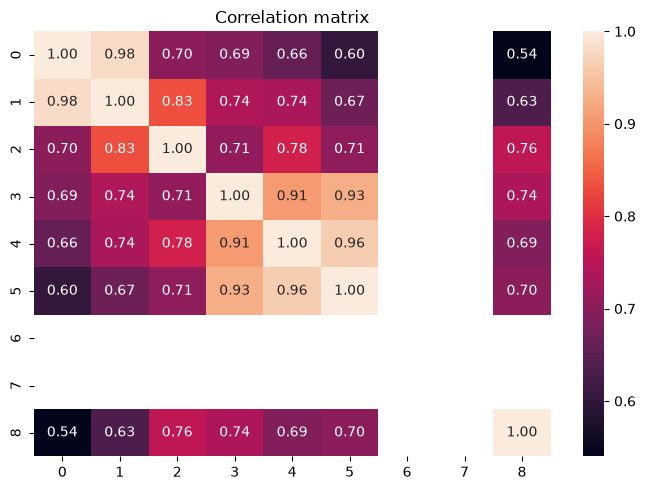

In [40]:
plt.figure(figsize=(7, 5))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
)
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()

In [81]:
dfs[3].head(7)

,year,period,periodName,latest,value,footnotes,filled,year-period
0,2026,M09,September,true,159044,"[{'code': 'P', 'text': 'preliminary'}]",False,2026-09
1,2026,M08,August,NaN,159015,"[{'code': 'P', 'text': 'preliminary'}]",False,2026-08
2,2026,M07,July,NaN,158882,[{}],False,2026-07
3,2026,M06,June,NaN,158892,[{}],False,2026-06
4,2026,M05,May,NaN,158861,[{}],False,2026-05
5,2026,M04,April,NaN,158798,[{}],False,2026-04
6,2026,M03,March,NaN,158650,[{}],False,2026-03


In [82]:
dfs[4].head(7)

,year,period,periodName,latest,value,footnotes,filled,year-period
0,2026,M09,September,true,37,"[{'code': 'P', 'text': 'preliminary'}]",False,2026-09
1,2026,M08,August,NaN,37,"[{'code': 'P', 'text': 'preliminary'}]",False,2026-08
2,2026,M07,July,NaN,37,[{}],False,2026-07
3,2026,M06,June,NaN,37,[{}],False,2026-06
4,2026,M05,May,NaN,37,[{}],False,2026-05
5,2026,M04,April,NaN,37,[{}],False,2026-04
6,2026,M03,March,NaN,37,[{}],False,2026-03


In [80]:
dfs[5].head(7)

,year,period,periodName,latest,value,footnotes,filled,year-period
0,2026,M09,September,true,32,"[{'code': 'P', 'text': 'preliminary'}]",False,2026-09
1,2026,M08,August,NaN,32,"[{'code': 'P', 'text': 'preliminary'}]",False,2026-08
2,2026,M07,July,NaN,32,[{}],False,2026-07
3,2026,M06,June,NaN,32,[{}],False,2026-06
4,2026,M05,May,NaN,32,[{}],False,2026-05
5,2026,M04,April,NaN,32,[{}],False,2026-04
6,2026,M03,March,NaN,32,[{}],False,2026-03


In [83]:
dfs[6].head(7)

,year,period,periodName,latest,value,footnotes,filled,year-period
0,2026,M09,September,true,34,"[{'code': 'P', 'text': 'preliminary'}]",False,2026-09
1,2026,M08,August,NaN,34,"[{'code': 'P', 'text': 'preliminary'}]",False,2026-08
2,2026,M07,July,NaN,34,[{}],False,2026-07
3,2026,M06,June,NaN,34,[{}],False,2026-06
4,2026,M05,May,NaN,34,[{}],False,2026-05
5,2026,M04,April,NaN,34,[{}],False,2026-04
6,2026,M03,March,NaN,34,[{}],False,2026-03


In [84]:
dfs[7].head(7)

,year,period,periodName,latest,value,footnotes,filled,year-period
0,2026,M09,September,true,33,"[{'code': 'P', 'text': 'preliminary'}]",False,2026-09
1,2026,M08,August,NaN,33,"[{'code': 'P', 'text': 'preliminary'}]",False,2026-08
2,2026,M07,July,NaN,33,[{}],False,2026-07
3,2026,M06,June,NaN,33,[{}],False,2026-06
4,2026,M05,May,NaN,33,[{}],False,2026-05
5,2026,M04,April,NaN,33,[{}],False,2026-04
6,2026,M03,March,NaN,33,[{}],False,2026-03


In [39]:
correlation_over_year_period = dfs[4][["year-period", "value"]].merge(
    dfs[5][["year-period", "value"]],
    on="year-period",
    suffixes=("_1", "_2")
)

correlation_over_year_period = correlation_over_year_period.sort_values("year-period")

correlation_over_year_period["correlation"] = (
    correlation_over_year_period["value_1"]
    .rolling(window=3)
    .corr(correlation_over_year_period["value_2"])
)

In [40]:
correlation_over_year_period.head(10)

,year-period,value_1,value_2,correlation
32,2024-01,34,29,NaN
31,2024-02,34,29,NaN
30,2024-03,34,29,NaN
29,2024-04,34,29,NaN
28,2024-05,34,29,NaN
27,2024-06,35,30,1.0
26,2024-07,35,30,1.0
25,2024-08,35,30,NaN
24,2024-09,35,30,NaN
23,2024-10,35,30,NaN


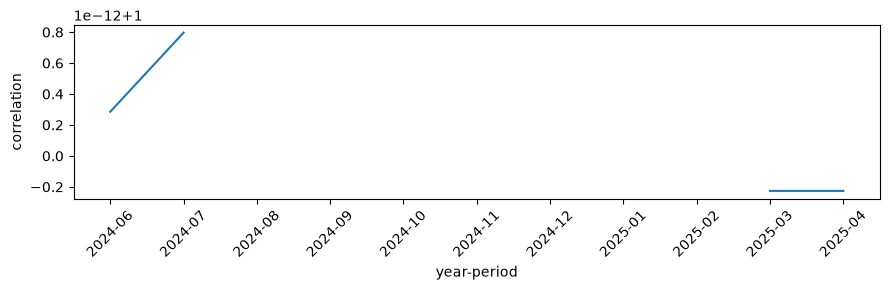

In [41]:
plt.figure(figsize=(9, 3))
plt.plot(
    correlation_over_year_period["year-period"],
    correlation_over_year_period["correlation"]
)
plt.xlabel("year-period")
plt.ylabel("correlation")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Datasets to Keep:
* dfs[0]
* dfs[2]
* dfs[3]
* dfs[8]

dfs[4], dfs[5], dfs[6], dfs[7] are constants


---


* "Civilian Labor Force (Seasonally Adjusted)": "LNS11000000",
* "Civilian Unemployment (Seasonally Adjusted)": "LNS13000000",
* "Unemployment Rate (Seasonally Adjusted)": "LNS14000000",
* "Total Private Average Hourly Earnings of Prod. and Nonsup. Employees - Seasonally Adjusted": "CES0500000008"